# <span style="font-size: 36px; font-weight: bold; color: #8B4513;">Machine Learning I - Group Project Nata Visionaries</span>



<font color='#8B4513'><b><span style="font-size: 20px;">|Notebook 1: Data Exploration|</span></b></font> <a class="anchor" id="P0"></a>

### <font color='#B8860B'>Table of Contents</font> <a class="anchor" id='toc'></a>

1. [Introduction](#Introduction)  
   1.1) Project Context  
   1.2) Objectives of the Data Exploration Phase  

2. [Data Overview](#Data-Overview)  
   2.1)Dataset Description  
   2.2) Feature Dictionary  

3. [Data Quality Assessment](#Data-Quality-Assessment)  
   3.1) Missing Values Overview  
   3.2) Duplicates and Data Consistency  
   3.3) Data Types Summary  

5. [Exploratory Data Visualization](#Exploratory-Data-Visualization)  
   - Numerical Feature Distributions  
   - Categorical Feature Frequencies  
   - Correlation Heatmap  
   - Relationships Between Price and Key Features  
   - Boxplots Across Categories (Brand, Fuel Type, Damage, etc.)  
   - Additional Insights (Paint Quality, Mileage, Engine Size)

6. [Key Insights & Summary](#Key-Insights-&-Summary)  
   - Observed Trends and Patterns  
   - Variables Potentially Impacting Price  
   - Insights to Guide Preprocessing & Modelling



<h2 style="color:#D4A017;">1.Introduction</h2>

The purpose of this notebook is to conduct an exploratory data analysis (EDA) of the dataset provided by the Nata Visionaries project.
This step aims to develop a comprehensive understanding of the available data, its structure, and the relationships among variables that may influence the quality classification of Pastéis de Nata.

<font color='#B8860B'>1.1 Project Context</font> <a class="anchor" id='Project-Context'></a>

The dataset contains measurements and process parameters collected from traditional bakeries in Porto and Lisbon.
Each record represents a unique production of Pastel de Nata, classified as either:

OK — meets the Nata Visionaries’ standards of excellence;

KO — acceptable, but not up to the brotherhood’s ideal of perfection.

Through this analysis, we aim to uncover the patterns and characteristics that distinguish these two classes and build a foundation for developing a predictive model capable of assessing pastry quality without destructive testing.

<font color='#B8860B'>1.2 Objectives of the Data Exploration Phase</font> <a class="anchor" id='Objectives'></a>

The exploratory data analysis (EDA) aims to:

- **Assess data quality and completeness**, including missing values, duplicates, and data types.  
- **Explore distributions** of numeric and categorical features to understand their behavior and identify potential outliers.  
- **Analyze relationships** between predictors and the target variable `quality_class`.  
- **Identify key insights and hypotheses** that can guide data preprocessing, feature engineering, and model development in subsequent notebooks.  


---
<h2 style="color:#D4A017;">2.Data Overview</h2>

In this section, we import the datasets provided for the Nata Visionaries project.  
The main dataset — `learn.csv` — contains both the predictor variables and the target variable (`quality_class`), which indicates whether each *Pastel de Nata* is classified as **OK** or **KO**.  

Additionally, we load the **data dictionary** (`data_dictionary.csv`) to better understand the meaning and units of each feature, as well as the structure of the other provided files (`predict.csv` and `sampred.csv`) for later use.  




<font color='#B8860B'>2.1 Dataset Description</font> <a class="anchor" id='Project-Context'></a>
#### Objective  
This subsection provides a concise overview of the dataset’s structure — its size, data types, and an initial preview of the content.  
The goal is to understand the type and amount of data available before performing any visual analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install seaborn

In [2]:
learn = pd.read_csv("Nata_Files/learn.csv")
predict = pd.read_csv("Nata_Files/predict.csv")

In [3]:
print("Training set shape:", learn.shape)
print("Prediction set shape:", predict.shape)

Training set shape: (5200, 18)
Prediction set shape: (1300, 17)



Initial Observations  

- The training dataset (`learn.csv`) contains **5200 observations and 18 features**, including the target variable `quality_class`.  
- The prediction dataset (`predict.csv`) has the same feature structure **minus the target variable**, as expected.  

In [4]:
learn.head()

,id,ambient_humidity,baking_duration,cooling_period,cream_fat_content,egg_temperature,egg_yolk_count,final_temperature,lemon_zest_ph,notes_baker,origin,oven_temperature,pastry_type,preheating_time,salt_ratio,sugar_content,vanilla_extract,quality_class
0,1,54.0,24.0,26.0,100.4,52.0,11.0,309.0,3.2,NaN,Lisboa,NaN,Pastel Nata,207.0,42.74,22.8,5.7,KO
1,2,66.0,37.0,34.0,98.0,46.0,10.0,317.0,3.3,NaN,Lisboa,306.0,NaN,245.0,41.73,11.6,4.0,KO
2,3,41.0,30.0,19.0,99.3,53.0,10.0,130.0,3.4,NaN,Porto,121.0,NaN,186.0,75.10,20.3,7.5,OK
3,4,62.0,24.0,48.0,98.0,115.0,9.0,354.0,3.3,NaN,Lisboa,357.0,Pastel de Nata,186.0,46.41,73.3,4.2,OK
4,5,55.0,21.0,34.0,100.1,48.0,9.0,211.0,3.0,NaN,Lisboa,202.0,Pastel de nata,218.0,56.52,80.1,6.0,KO


In [5]:
predict.head()

,id,ambient_humidity,baking_duration,cooling_period,cream_fat_content,egg_temperature,egg_yolk_count,final_temperature,lemon_zest_ph,notes_baker,origin,oven_temperature,pastry_type,preheating_time,salt_ratio,sugar_content,vanilla_extract
0,5201,79.0,22,40,98.6,79.0,9.0,259.0,3.2,NaN,Lisboa,268.0,NaN,208.0,49.63,182.6,4.0
1,5202,49.0,26,32,101.9,105.0,9.0,287.0,3.2,NaN,Lisboa,287.0,Pastel de nata,189.0,182.54,76.2,4.8
2,5203,80.0,28,24,96.6,20.0,10.0,64.0,3.4,NaN,Porto,74.0,Pastel Nata,201.0,100.41,23.5,6.1
3,5204,74.0,21,37,97.2,81.0,9.0,314.0,3.0,NaN,Lisboa,317.0,NaN,220.0,46.66,143.2,4.9
4,5205,41.0,19,41,97.3,104.0,10.0,246.0,3.2,NaN,Lisboa,243.0,Pastel Nata,191.0,39.45,143.0,7.0


In [6]:
learn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5200 non-null   int64  
 1   ambient_humidity   5182 non-null   float64
 2   baking_duration    5199 non-null   float64
 3   cooling_period     5199 non-null   float64
 4   cream_fat_content  5176 non-null   float64
 5   egg_temperature    5176 non-null   float64
 6   egg_yolk_count     5176 non-null   float64
 7   final_temperature  5175 non-null   float64
 8   lemon_zest_ph      5174 non-null   float64
 9   notes_baker        0 non-null      float64
 10  origin             5039 non-null   object 
 11  oven_temperature   5179 non-null   float64
 12  pastry_type        3411 non-null   object 
 13  preheating_time    5181 non-null   float64
 14  salt_ratio         5187 non-null   float64
 15  sugar_content      5178 non-null   float64
 16  vanilla_extract    5182 

- Most features are **numeric**, except for the categorical variable `origin` and `pastry_type`.  

Next, we will proceed to analyze the **data structure, feature types, missing values, and summary statistics** to better understand the dataset and prepare for preprocessing.

---

In [7]:
learn.describe().T

,count,mean,std,min,25%,50%,75%,max
id,5200.0,2600.500000,1501.255031,1.00,1300.75,2600.50,3900.250,5200.00
ambient_humidity,5182.0,59.980316,11.616151,40.00,50.00,60.00,70.000,80.00
baking_duration,5199.0,26.979804,8.320079,14.00,21.00,25.00,30.000,89.00
cooling_period,5199.0,31.817850,14.427143,0.00,25.00,31.00,39.000,105.00
cream_fat_content,5176.0,98.413060,1.997350,91.90,97.10,98.40,99.800,107.30
egg_temperature,5176.0,70.812403,35.439831,12.00,44.00,67.00,92.000,575.00
egg_yolk_count,5176.0,10.498068,1.257709,8.00,10.00,10.00,11.000,15.00
final_temperature,5175.0,223.577198,85.258779,31.00,164.00,226.00,284.000,722.00
lemon_zest_ph,5174.0,3.218902,0.165909,2.70,3.10,3.20,3.300,4.00
notes_baker,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
learn.columns

Index(['id', 'ambient_humidity', 'baking_duration', 'cooling_period',
       'cream_fat_content', 'egg_temperature', 'egg_yolk_count',
       'final_temperature', 'lemon_zest_ph', 'notes_baker', 'origin',
       'oven_temperature', 'pastry_type', 'preheating_time', 'salt_ratio',
       'sugar_content', 'vanilla_extract', 'quality_class'],
      dtype='object')

### `notes_baker` Column Observation  

The variable **`notes_baker`** appears to contain **no recorded data** in this dataset (count = 0).  
It was likely intended for qualitative input from the bakers, such as comments or remarks about the batch, but this information is missing for all observations.

Since the column provides **no usable data** and cannot contribute to numerical or categorical analysis, it will likely be **dropped during preprocessing** in the next notebook.

> *Decision:* in the second notebook will remove `notes_baker` column due to 100% missing values.


<font color='#B8860B'>2.2 Feature Selection</font> <a class="anchor" id='Project-Context'></a>

#### Objective  
This subsection summarizes the meaning of each feature in the dataset.  
Understanding the role of every attribute is essential before visualizing or modelling, as it helps identify which variables are numerical, categorical, or target-related.

---

| **Feature** | **Description** |
|:---|:---|
| **carID** | Unique identifier for each car in the dataset |
| **Brand** | Manufacturer or brand of the car (e.g. Ford, Toyota, BMW) |
| **model** | Specific model designation under the brand |
| **year** | Year the car was registered |
| **mileage** | Total distance the car has travelled (in miles) |
| **tax** | Applicable road tax (£) for the car (based on 2020 regulations) |
| **fuelType** | Type of fuel used (Diesel, Petrol, Hybrid, Electric) |
| **mpg** | Average miles per gallon (fuel efficiency measure) |
| **engineSize** | Engine capacity in liters (cubic decimeters) |
| **paintQuality%** | Mechanic’s paint and body integrity evaluation (percentage) |
| **previousOwners** | Number of previous registered owners |
| **hasDamage** | Indicates whether the seller reported any damage (Boolean) |
| **price** | Target variable — car purchase price by Cars 4 You (£) |

---

####  Notes
- The **target variable** for regression is **`price`**.  
- Variables such as **`Brand`**, **`model`**, and **`fuelType`** are **categorical**, whereas **`mileage`**, **`mpg`**, and **`engineSize`** are **numerical**.  
- The **`paintQuality%`** and **`hasDamage`** fields relate to the **physical condition** of the car, likely influencing its market value.

---


---
<h2 style="color:#D4A017;">3.Data Quality Assessment</h2>
<font color='#B8860B'>3.1) Missing Values Overview</font> <a class="anchor" id='Project-Context'></a>


After removing the empty `notes_baker` column, we proceed to examine the remaining features for missing values.  
Understanding the presence and distribution of missing data is essential before preprocessing, as it can impact model performance and introduce bias if not handled properly.

In this section, we will:
- Identify which variables contain missing values;
- Quantify the percentage of missing data per column;
- Visualize the missingness pattern using a heatmap.

This analysis will inform the imputation strategy to be applied later in the preprocessing stage.




###  Step 1: Identify which variables contain missing values  
Before quantifying or visualizing the missing data, it’s important to know **which columns** contain null or empty entries.  
The code below uses `isnull().sum()` to count the number of missing observations per feature.  


In [9]:
learn.isnull().sum()

id                      0
ambient_humidity       18
baking_duration         1
cooling_period          1
cream_fat_content      24
egg_temperature        24
egg_yolk_count         24
final_temperature      25
lemon_zest_ph          26
notes_baker          5200
origin                161
oven_temperature       21
pastry_type          1789
preheating_time        19
salt_ratio             13
sugar_content          22
vanilla_extract        18
quality_class           1
dtype: int64


### Step 2: Quantify the percentage of missing data per column  
While absolute counts are informative, percentages give a clearer sense of how much of each feature’s data is missing.
In the following code, we calculate both the count and percentage of missing values and present them in a sorted table for easier interpretation.


In [10]:
missing_counts=learn.isnull().sum()
missing_percentage= (missing_counts/len(learn))*100

In [11]:
missing_data= pd.DataFrame({'Missing Values':missing_counts,
                            'Percentage': missing_percentage}).sort_values(by='Percentage',ascending=False)
missing_data

,Missing Values,Percentage
notes_baker,5200,100.000000
pastry_type,1789,34.403846
origin,161,3.096154
lemon_zest_ph,26,0.500000
final_temperature,25,0.480769
cream_fat_content,24,0.461538
egg_temperature,24,0.461538
egg_yolk_count,24,0.461538
sugar_content,22,0.423077
oven_temperature,21,0.403846


### Missing Values Analysis:

The table above shows the number of missing values for each feature. Key insights include:

- **`origin`** has 161 missing values, which represents about **5%** of the dataset. This will need attention, possibly through imputation or removal.
- **`pastry_type`** has 1789 missing values, accounting for approximately **59%** of the data, which is significant and may require dropping or careful imputation.
- **`quality_class`** has only 1 missing value, representing less than **0.1%**, which can be easily handled.
- Other features like **`cream_fat_content`** (24 missing values) and **`egg_temperature`** (24 missing values) represent around **1%** of the data and can likely be imputed or dropped without major impact.

This helps us identify where to focus our data cleaning efforts, particularly on columns with high percentages of missing values.


### Step 3: Visualize the missingness pattern using a heatmap    
The following heatmap provides a visual overview of the distribution of missing values across all records:

- Each **row** on the y-axis represents a single observation in the dataset.  
- Each **column** on the x-axis corresponds to one feature.  
- **Yellow cells** indicate missing values (`NaN`), while **dark cells** indicate valid data.

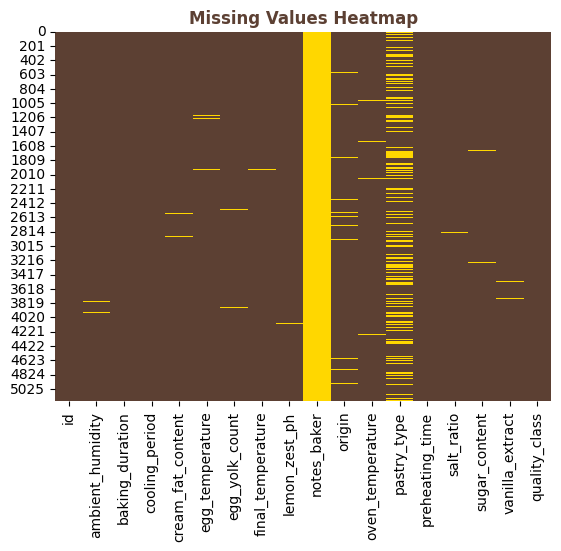

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
cmap_brown_yellow = LinearSegmentedColormap.from_list("brown_yellow", ["#5C4033", "#FFD700"]) 

sns.heatmap(learn.isnull(), cbar=False, cmap=cmap_brown_yellow)
plt.title('Missing Values Heatmap', fontsize=12, fontweight='bold', color='#5C4033')
plt.show()


From the visualization, we can confirm that:
- Missing values are scattered rather than concentrated in specific observations, meaning there is **no clear pattern of missingness** (e.g., entire rows missing).  
- Features such as `pastry_type` and `origin` show noticeable vertical lines, confirming higher proportions of missing data.  
- Other variables (like `cream_fat_content`, `egg_temperature`, `lemon_zest_ph`) show occasional gaps but remain mostly complete.  
- The remaining columns appear nearly full, suggesting that most features are reliable for analysis.

This visual confirmation supports our earlier numeric findings and will guide how we handle missing values in the preprocessing stage.

<font color='#B8860B'>3.2) Duplicates and Data Consistency</font> <a class="anchor" id='Project-Context'></a>

#### Objective  
This subsection aims to **identify potential duplicate records** and **check for consistency** in key attributes.  
These checks ensure that the dataset does not contain redundant or conflicting information before any modeling or visualization is performed.

---

In [13]:
duplicate_count = learn.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    display(df[df.duplicated()])
else:
    print("No duplicate rows detected in the dataset.")

Number of duplicate rows: 0
No duplicate rows detected in the dataset.


<font color='#B8860B'>3.3) Data Types Summary</font> <a class="anchor" id='Project-Context'></a>

#### Objective  
This subsection summarizes the **data types** of all features in the dataset.  
Understanding the type of each variable (numeric, categorical, boolean, etc.) is essential to guide the appropriate **visualization and modeling strategies** later on.


In [14]:
data_types = pd.DataFrame({
    'Data Type': learn.dtypes,
    'Unique Values': learn.nunique(),
    'Missing Values': learn.isnull().sum()
}).sort_values(by='Data Type')

display(data_types)

,Data Type,Unique Values,Missing Values
id,int64,5200,0
sugar_content,float64,1426,22
salt_ratio,float64,3560,13
preheating_time,float64,260,19
oven_temperature,float64,380,21
notes_baker,float64,0,5200
vanilla_extract,float64,108,18
lemon_zest_ph,float64,14,26
egg_yolk_count,float64,8,24
egg_temperature,float64,187,24


<h2 style="color:#D4A017;">4.Exploratory Data Visualization</h2>

In this section, we explore the statistical properties and distributions of each feature to better understand their ranges, patterns, and potential anomalies.  
This step helps identify:
- Features with strong variability or skewness;
- Outliers that might require scaling or transformation;
- Variables that may need normalization before modeling.

We will start by examining the **numerical features** through summary statistics, histograms, and boxplots, and then analyse the **categorical variables** to understand their frequency distributions.  


In [15]:
num_cols= learn.select_dtypes(include=['float64','int64']).columns.tolist()
cat_cols= learn.select_dtypes(include=['object']).columns.tolist()

In [16]:
print('Numeric features:\n',num_cols)

Numeric features:
 ['id', 'ambient_humidity', 'baking_duration', 'cooling_period', 'cream_fat_content', 'egg_temperature', 'egg_yolk_count', 'final_temperature', 'lemon_zest_ph', 'notes_baker', 'oven_temperature', 'preheating_time', 'salt_ratio', 'sugar_content', 'vanilla_extract']


In [17]:
print('Categorical features:\n',cat_cols)

Categorical features:
 ['origin', 'pastry_type', 'quality_class']


We’ve already reviewed the summary statistics earlier, so here we focus on visual exploration.  
Let’s look at how the numerical features are distributed to identify skewness, variability, and possible outliers.


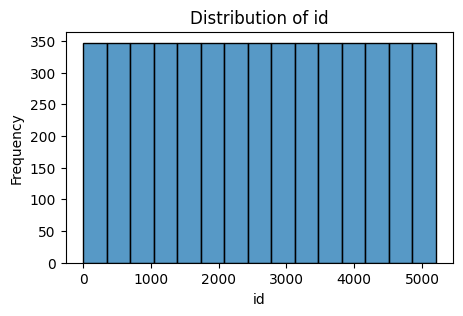

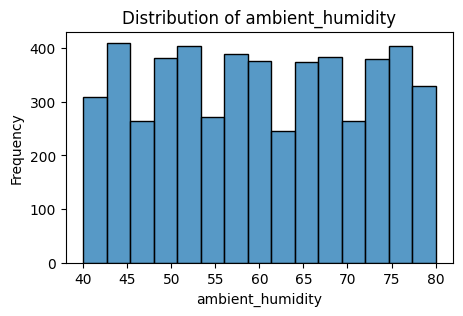

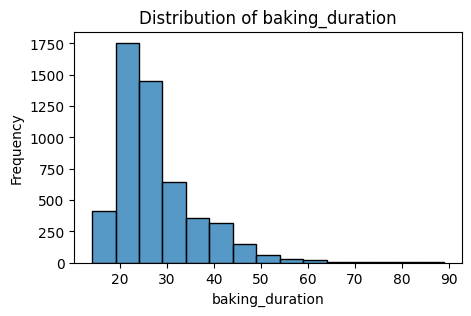

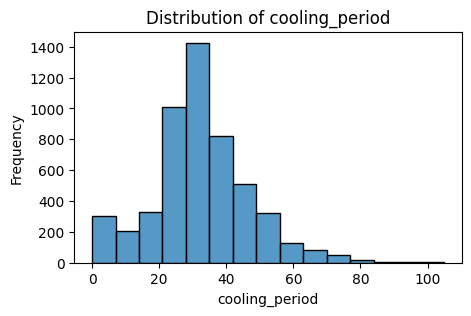

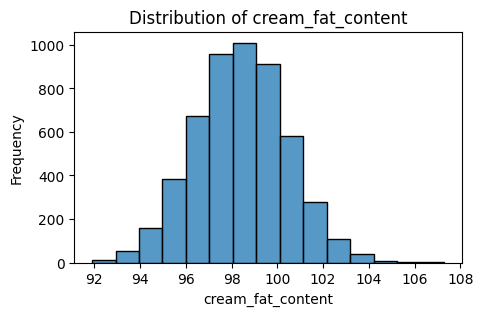

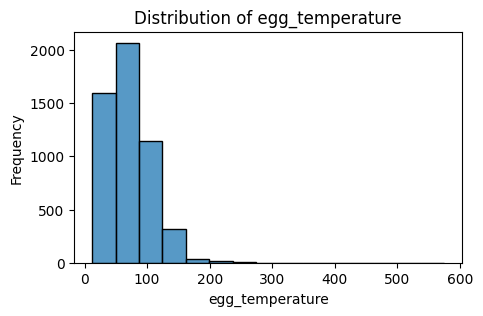

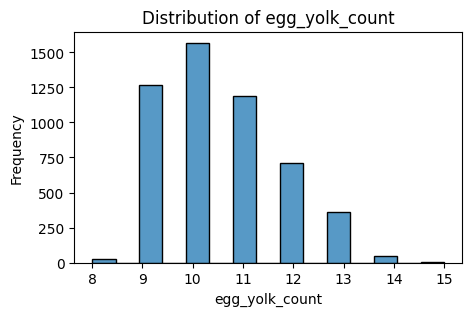

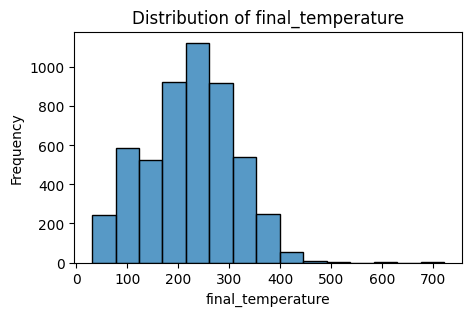

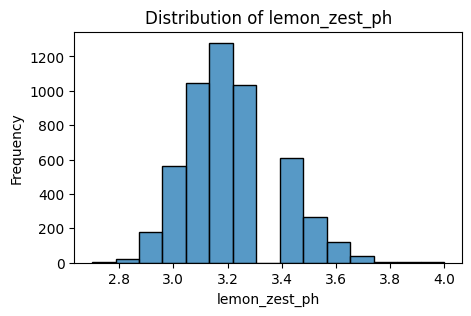

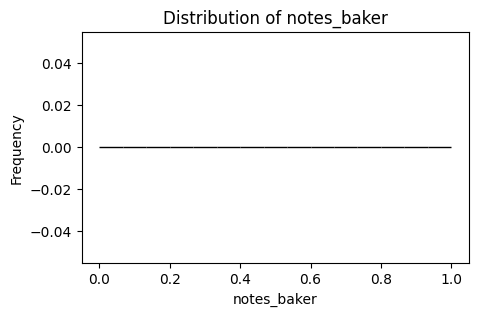

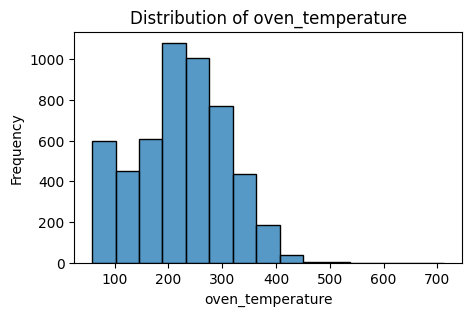

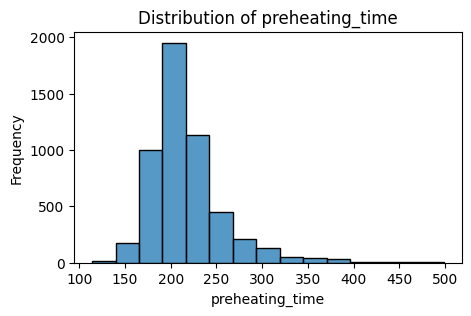

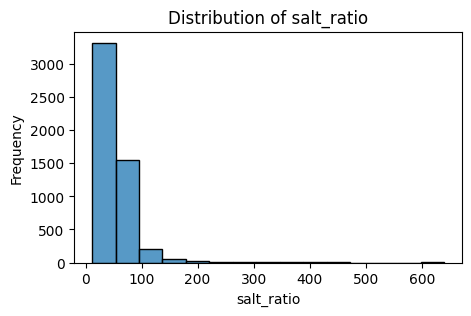

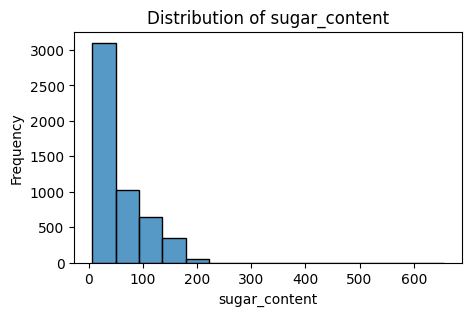

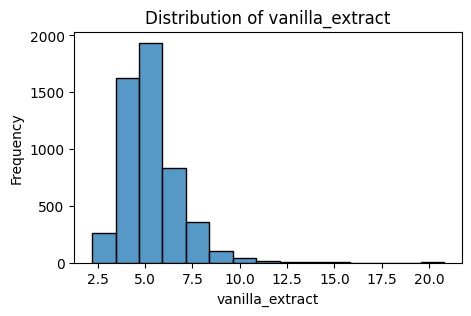

In [18]:
for col in num_cols:
    plt.figure(figsize=(5, 3))
    sns.histplot(data=learn, x=col, bins=15)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

These histograms show how each numerical feature is distributed, allowing us to assess three key aspects of the data:

- **Skewness** — If a distribution leans heavily to one side, it means the data are not symmetric.  
  Strongly skewed features may require scaling or transformation (for example, a log transform) so that models don’t give too much importance to extreme values.

- **Variability** — The width of the distribution shows how spread out the data are.  
  Features with high variability can dominate the learning process, while those with very low variability may contribute little useful information.

- **Possible outliers** — Isolated bars or small peaks far from the main group of values may indicate outliers.  
  These could represent unusual production conditions or measurement errors and should be reviewed before modeling.

Understanding these patterns helps decide whether normalization, transformation, or outlier treatment will be necessary in preprocessing.



Next, we use boxplots to examine the spread of each numerical feature (without the ID column) and identify potential outliers.  
Boxplots show the median, quartiles, and any values that fall far from the rest of the data, which can indicate unusual observations or variability in production.


In [19]:
no_id=num_cols[1:]

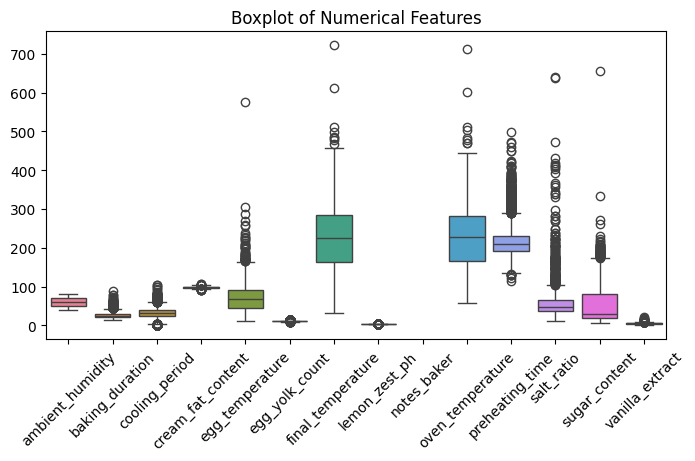

In [20]:
plt.figure(figsize=(8,4))
sns.boxplot(data=learn[no_id])
plt.title('Boxplot of Numerical Features')
plt.xticks(rotation=45)
plt.show()

The boxplots highlight how each numerical feature varies and where outliers may exist:

- **Median and spread** — The line inside each box shows the median, while the box width reflects variability.  
- **Outliers** — Points beyond the whiskers represent unusually high or low values.  
  These could come from experimental variations or data entry errors.  
- **Comparing spreads** — Features with much wider boxes show greater variability, which might require normalization before modeling.

This visualization gives a clearer picture of the data’s consistency and helps identify features that might need special preprocessing.  
Now we explore the categorical features to see how their categories are distributed in the dataset. 


Firstly, we check the different entries of each variable to ensure that similar values are written consistently across the dataset.


In [21]:
for col in cat_cols:
    print(f'Value counts for each column\n')
    print(learn[col].value_counts())

Value counts for each column

origin
Lisboa     3486
Porto      1167
LISBOA      119
Lisboa       88
lisboa       83
PORTO        33
Porto        25
 Lisboa      20
porto        15
 Porto        3
Name: count, dtype: int64
Value counts for each column

pastry_type
Pastel Nata       879
Pastel de Nata    859
Pastel de nata    840
Pastel De Nata    833
Name: count, dtype: int64
Value counts for each column

quality_class
OK    3302
KO    1897
Name: count, dtype: int64


The results above show that some categories are written in different ways but represent the same value.  
For instance, the variable `origin` contains several versions of "Lisboa" and "Porto" with different capitalizations and spaces,  
and the variable `pastry_type` includes multiple variations of "Pastel de Nata".  

Next, we will standardize these entries so that each category is represented consistently across the dataset.


In [22]:
learn['pastry_type'] = learn['pastry_type'].str.lower().replace({'pastel nata': 'pastel de nata'})

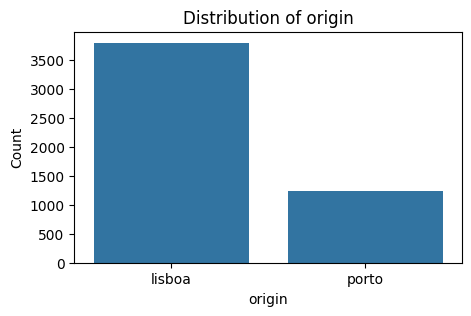

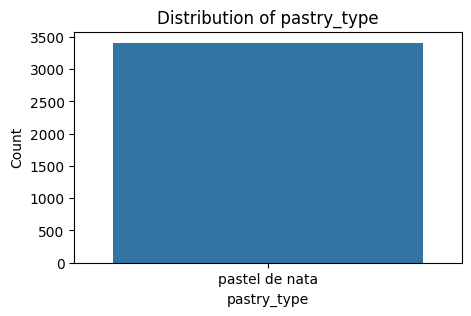

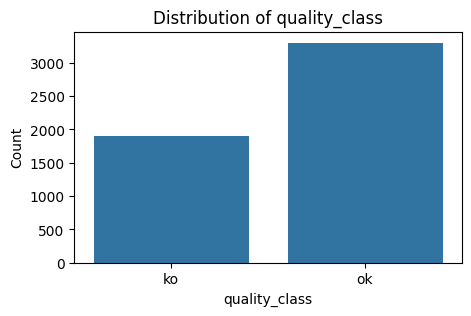

In [23]:
for col in cat_cols:
    learn[col]=learn[col].str.strip().str.lower()
    plt.figure(figsize=(5,3))
    sns.countplot(data=learn, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

After standardizing the categorical variables, the different versions of the same entries are now combined into single categories, making the data consistent.

The countplots above show how often each category appears in the dataset.  
They help visualize whether the categories are balanced or if some dominate the data.  
In this case, we can see that the variable `origin` still has two main categories, while `pastry_type` contains only one unique value after standardization.  
This means that `pastry_type` will not provide useful information for predicting the target variable, since there is no variation in its values.


---
Relationship with Target (quality_class)

In this section, we explore how each feature relates to the target variable `quality_class`, which indicates whether a Pastel de Nata is classified as **OK** or **KO**.  

By comparing the distributions of the features between these two classes, we can identify which variables show clear differences and might have a stronger influence on the final quality.  
This analysis helps highlight the most relevant factors to consider when building predictive models later on.


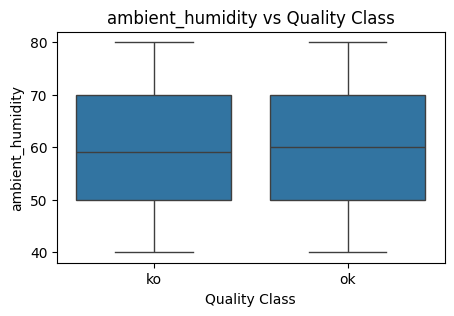

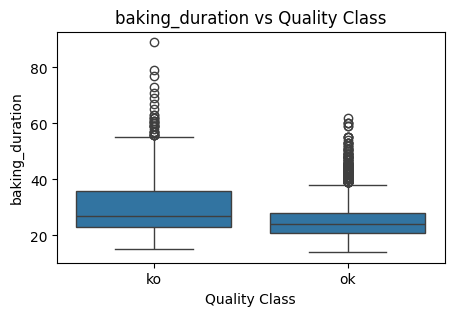

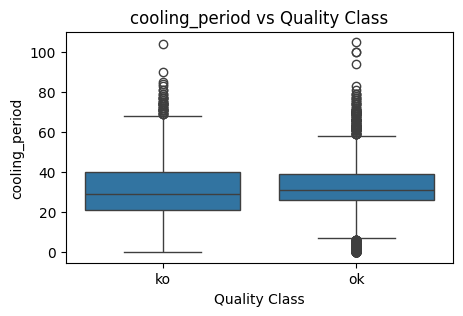

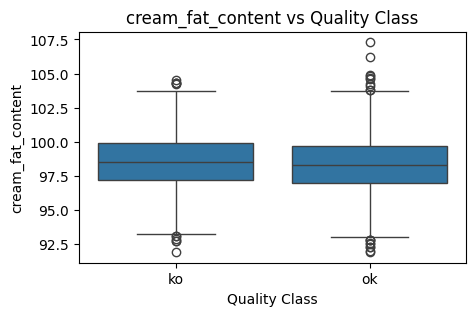

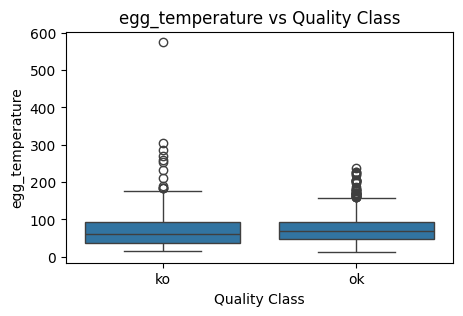

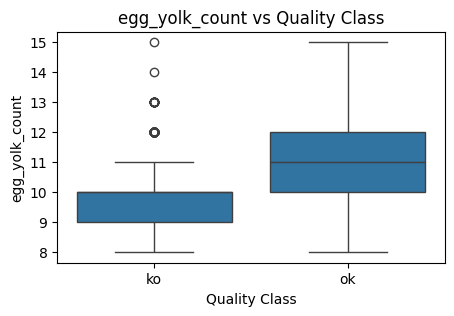

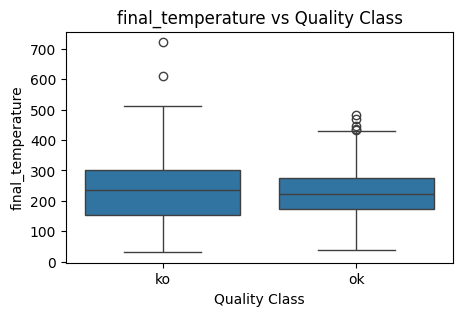

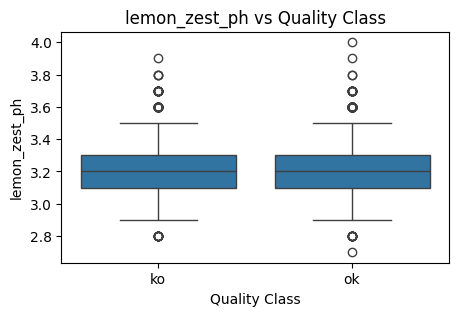

ValueError: List of boxplot statistics and `positions` values must have same the length

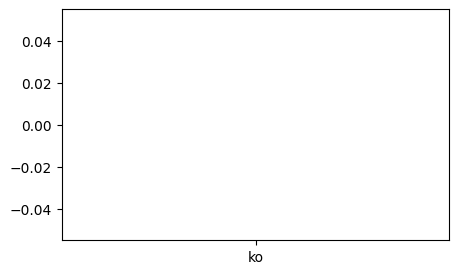

In [24]:
for col in no_id:
    plt.figure(figsize=(5,3))
    sns.boxplot(data=learn, x='quality_class', y=col)
    plt.title(f'{col} vs Quality Class')
    plt.xlabel('Quality Class')
    plt.ylabel(col)
    plt.show()

These boxplots show how each numerical feature differs between OK and KO samples.  
We can look for:
- **Different medians** — if one class consistently has higher or lower values, it may affect quality.  
- **Spread differences** — wider boxes suggest more variability in that feature for a given class.  
- **Overlapping ranges** — when the boxes overlap heavily, that variable may have less discriminative power.

Features with noticeable differences between classes are strong candidates for influencing pastry quality.


We now compare each categorical feature with the target variable `quality_class`, excluding the class itself since it is the variable we are trying to predict.


In [ ]:
cat_cols=[col for col in cat_cols if col!='quality_class']

In [ ]:
for col in cat_cols:
    plt.figure(figsize=(5,3))
    sns.countplot(data=learn, x=col, hue='quality_class')
    plt.title(f"{col} vs quality_class")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend(title='Quality')
    plt.show()

These countplots show how the categorical features are distributed across the two classes of the target variable `quality_class`.  
They allow us to see whether certain categories are more commonly associated with OK or KO outcomes.  

From the plots, we can observe that:
- The variable `origin` shows some differences between the two classes, which might indicate that the bakery location influences the final quality.  
- The variable `pastry_type` only contains one category, so it does not contribute useful information for distinguishing between OK and KO pastries.  

This analysis helps identify which categorical variables could provide meaningful insights for predicting pastry quality.


<h2 style="color:#D4A017;">5.Key Insights & Summary</h2>